### Build a basic chatbot with langgraph (Graph API)

In [65]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [66]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated.
    # here, it appends new messages to the list
    messages: Annotated[list, add_messages]


In [67]:
import os
from dotenv import load_dotenv
load_dotenv()


True

In [68]:
print(bool(os.getenv("TAVILY_API_KEY")))
print(bool(os.getenv("GROQ_API_KEY")))

True
True


In [69]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="qwen/qwen3.8-27b")

In [70]:
## Node Functionality
def chatbot(state:State):
    return {"messages": [llm.invoke(state["messages"])]}

In [71]:
## build the graph
graph_builder = StateGraph(State) 

## adding nodes
graph_builder.add_node("llmchatbot", chatbot)

## adding edges
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)

## compile the graph
graph=graph_builder.compile()


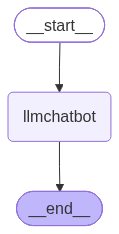

In [72]:
## visualize the graph
from IPython.display import Image, display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass


In [73]:
## running the graph
response = graph.invoke({"messages": "Hi"}) ## treated as human message
response

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='e59628a2-cc3b-475c-aead-923ebe41f69a'),
  AIMessage(content='Hello! How can I help you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 13, 'total_tokens': 23, 'completion_time': 0.019253597, 'completion_tokens_details': None, 'prompt_time': 0.000597472, 'prompt_tokens_details': None, 'queue_time': 0.049237337, 'total_time': 0.019851069}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a21211-aba1-778b-bd17-06e30e840fa1-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_tokens': 10, 'total_tokens': 23})]}

In [74]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [75]:
## ways of streaming the response from the graph
for event in graph.stream({"messages": "Hi, How are you?"}): ## treated as human message
    for value in event.values():
        print(value["messages"][-1].content)

I'm doing well, thank you for asking! How are you doing today? Is there anything specific I can help you with?


### Chatbot with Tool

In [76]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=2)
tool.invoke("What is langgraph?")

{'query': 'What is langgraph?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] LangGraph illuminates the processes within an AI workflow, allowing full transparency of the agent’s state. Within LangGraph, the “state” feature serves as a memory bank that records and tracks all the valuable information processed by the AI system. It’s similar to a digital notebook where the system captures a

In [77]:
## custom function
def multiply(a: int, b:int) -> int:
    '''
    Multiply a and b
    
    Args: 
    a (int): first int
    b (int): second int
    
    Returns:
    int: output int
    '''

In [78]:
tools = [tool, multiply]

In [79]:
llm_with_tool = llm.bind_tools(tools) # binding the tools to the llm

In [80]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'Qwen3.8 27B', 'status': 'beta', 'release_date': '2026-08-14', 'last_updated': '2026-08-14', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x113416650>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x113416fd0>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for co

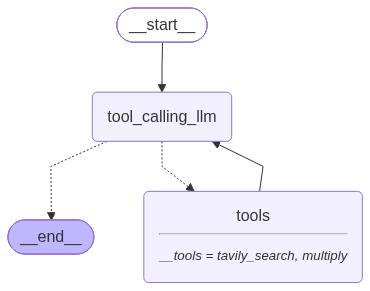

In [ ]:
# Creating stategraph with tools
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode # required imports
from langgraph.prebuilt import tools_condition

# Node definition
def tool_calling_llm(state:State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}
    

# Graph definition
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

# adding edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # if the latest message(result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message(result) from assistant is not a tool call -> tools_conditions routes to END
    tools_condition
    )
builder.add_edge("tools", END)

# compile the graph
graph=builder.compile()

from IPython.display import Image, display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as error:
    print(f"Could not render graph: {error}")
